<a href="https://colab.research.google.com/github/BranMerx/Airbnb-Data-Analysis/blob/main/Airbnb_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**AirBnB Exploratory Data Analysis**

AirBnB is a global online marketplace that connects travelers with unique lodging options. It offers a diverse range of accomodations in various destinations.

The importance of Analayizing AirBnB Booking Data:


*   Analayzing Market Trends
*   Identifying Profitable Locations
*   Optimizing Pricing Strategies
*   Enhancing Customer Experience



**Data Preprocessing**
This is the process of transforming the raw data into a suitable format for analysis or machine learning. It involves various techniques to clean, transform, and prepare the data, ensuring its quality and suitability for the intended use.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Loading dataset
file_path = "/content/Airbnb_Open_Data.csv"
df = pd.read_csv(file_path)

#Displaying first few rows of the dataset
df.head(4)

/tmp/ipykernel_1088/1577742170.py:7: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN


In [3]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

Checking the missing values in the dataset.

In [4]:
print(df.isnull().sum())

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

Handles the missing values in the dataset.

In [5]:
# Convert 'last review' to datetime and handle errors
df['last review'] = pd.to_datetime(df['last review'], errors='coerce')

# Fill missing values
df.fillna({'reviews per month': 0, 'last review': df['last review'].min()}, inplace=True)

# Drop records with missing 'name' or 'host name'
df.dropna(subset=['NAME', 'host name'], inplace=True)

In [6]:
#Correcting data types
# Remove dollar signs and convert to float
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)

<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:4: SyntaxWarning: invalid escape sequence '\$'
<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:4: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_1088/1837909990.py:3: SyntaxWarning: invalid escape sequence '\$'
  df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
/tmp/ipykernel_1088/1837909990.py:4: SyntaxWarning: invalid escape sequence '\$'
  df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)


In [7]:
df.drop_duplicates(inplace=True)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 101410 entries, 0 to 102057
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              101410 non-null  int64         
 1   NAME                            101410 non-null  object        
 2   host id                         101410 non-null  int64         
 3   host_identity_verified          101134 non-null  object        
 4   host name                       101410 non-null  object        
 5   neighbourhood group             101384 non-null  object        
 6   neighbourhood                   101394 non-null  object        
 7   lat                             101402 non-null  float64       
 8   long                            101402 non-null  float64       
 9   country                         100884 non-null  object        
 10  country code                    101288 non-null  object      

In [9]:
#Descriptive statistics
print(df.describe())
#Generates stats that summarize the central tendency,
#dispersion, and shape of a dataset's distribution, excluding NaN values


                 id       host id            lat           long  \
count  1.014100e+05  1.014100e+05  101402.000000  101402.000000   
mean   2.920959e+07  4.926155e+10      40.728082     -73.949663   
min    1.001254e+06  1.236005e+08      40.499790     -74.249840   
25%    1.507574e+07  2.459183e+10      40.688730     -73.982570   
50%    2.922911e+07  4.912069e+10      40.722300     -73.954440   
75%    4.328308e+07  7.399747e+10      40.762750     -73.932340   
max    5.736742e+07  9.876313e+10      40.916970     -73.705220   
std    1.626820e+07  2.853703e+10       0.055850       0.049474   

       Construction year          price    service fee  minimum nights  \
count      101210.000000  101171.000000  101142.000000   101016.000000   
mean         2012.486908     625.381008     125.043998        8.113744   
min          2003.000000      50.000000      10.000000    -1223.000000   
25%          2007.000000     340.000000      68.000000        2.000000   
50%          2012.000000  

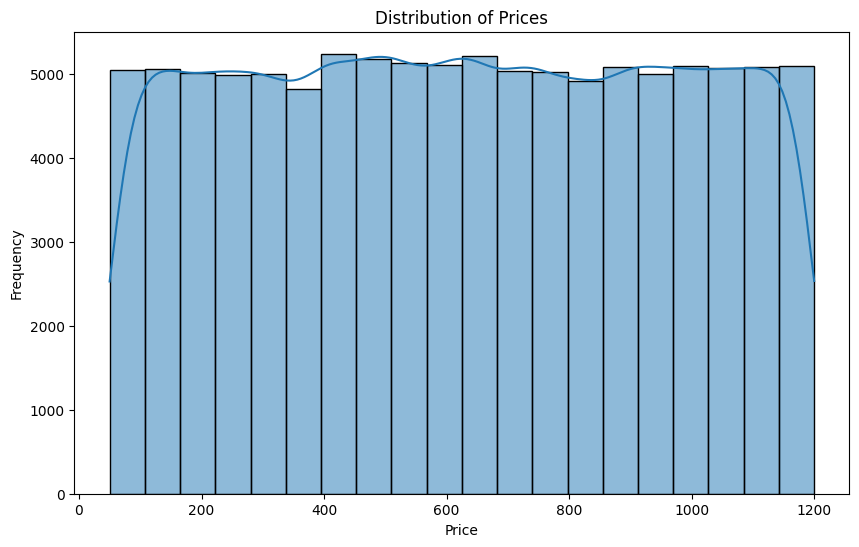

In [10]:
#Visualization
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=20, kde=True)
plt.title('Distribution of Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()
#Plotting the distribution of listing prices

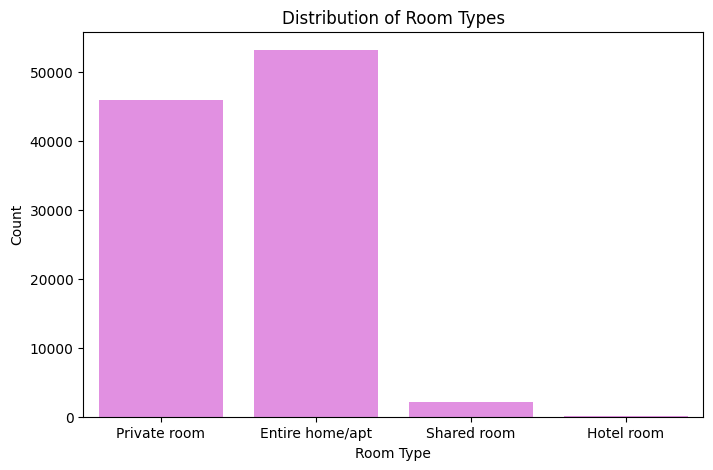

In [11]:
#Analyzing distribution of different room types
plt.figure(figsize=(8,5))
sns.countplot(x='room type', data=df, color='violet')
plt.title('Distribution of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()
#

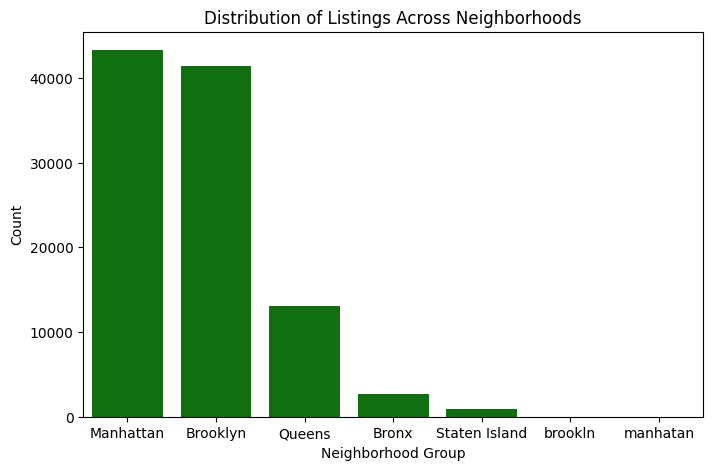

In [12]:
#Examination on how listings are distrbuted across different neighborhoods
plt.figure(figsize=(8,5))
sns.countplot(x='neighbourhood group', data=df, color='green',
order=df['neighbourhood group'].value_counts().index)
plt.title('Distribution of Listings Across Neighborhoods')
plt.xlabel('Neighborhood Group')
plt.ylabel('Count')
plt.show()

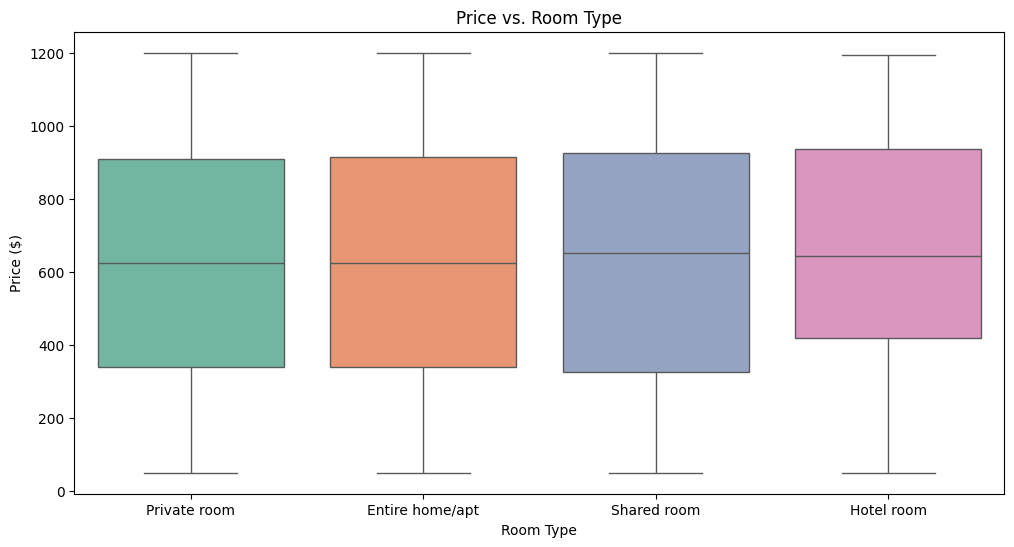

In [15]:
#Visual of the relationship between price and room type
plt.figure(figsize=(12,6))
sns.boxplot(x='room type', y = 'price', hue ='room type', data=df,
palette='Set2')
plt.title('Price vs. Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.show()

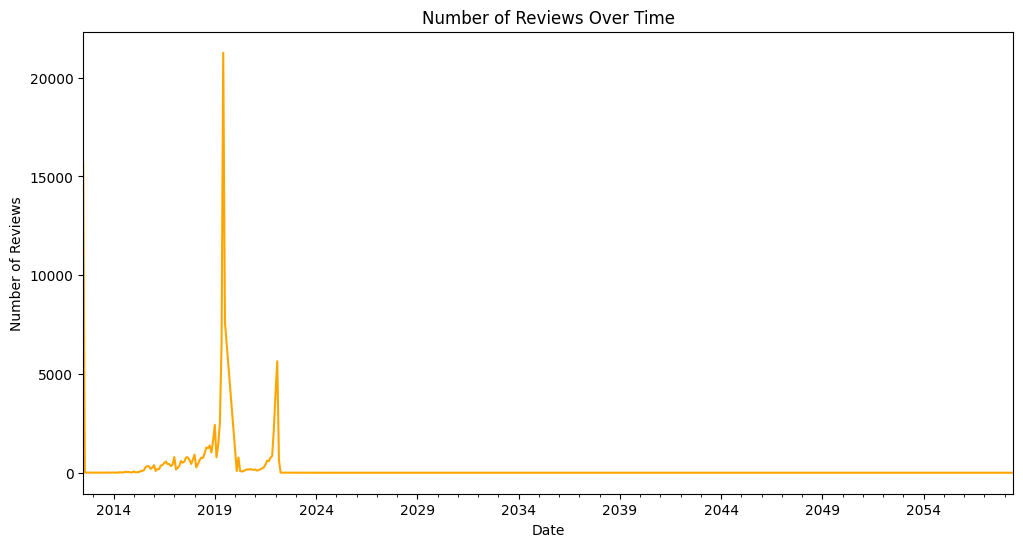

In [14]:
#Reviews over time
df['last review'] = pd.to_datetime(df['last review'])
reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size()

plt.figure(figsize=(12, 6))
reviews_over_time.plot(kind='line',color='Orange')
plt.title('Number of Reviews Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.show()

**Key Insights from Exploratory Data Analysis of AirBnB Dataset**

*Pricing Distribution:*
Most Airbnb listings are priced within a moderate range.
There are a few high-priced outliers, indicating some premium listings with significantly higher prices.

*Room Type Distribution:*
The majority of listings are either entire homes/apartments or private rooms.
Shared rooms and hotel rooms constitute a very small portion of the listings.

*Geographical Distribution:*
Listings are predominantly concentrated in popular areas like Brooklyn and Manhattan.
Other boroughs such as Queens, Bronx, and Staten Island have fewer listings.

*Price Comparison by Room Type:*
Entire homes/apartments generally cost more than private rooms.
Shared rooms tend to have the lowest prices among the room types.

*Seasonal Trends in Reviews:*
There are observable seasonal trends in the number of reviews.
Certain months experience higher review activity,